# Classification des changements urbains à partir d'images satellites

**Objectif :** à partir d'un polygone repéré sur une série de 5 images satellites prises à des dates différentes, prédire le type de changement survenu parmi 6 classes : démolition, route, résidentiel, commercial, industriel, méga-projet.

**Démarche :**
1. Explorer les données et leur déséquilibre
2. Construire des variables : type de zone, géométrie du polygone, chronologie des images, avancement du chantier, évolution des couleurs
3. Mettre en place une validation croisée **par zone géographique**, pour mesurer honnêtement la capacité à généraliser
4. Comparer plusieurs modèles, traiter le déséquilibre des classes et régler les hyperparamètres
5. Analyser les erreurs et l'importance des variables
6. Produire la soumission finale

La métrique principale est le **F1 macro** : la moyenne des F1 de chaque classe, qui donne le même poids aux classes rares qu'aux classes fréquentes.

In [1]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold,
                                     StratifiedKFold, cross_val_predict, cross_validate)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.features import CLASSES, load_dataset

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.figsize'] = (10, 4)
SEED = 42
N_JOBS = -1

TRAIN_PATH = os.environ.get('TRAIN_PATH', 'data/train.geojson')
TEST_PATH = os.environ.get('TEST_PATH', 'data/test.geojson')

## 1. Chargement et construction des variables

Toute la préparation est regroupée dans `src/features.py`, appliquée de la même façon à l'entraînement et au test. Chaque transformation ne dépend que de la ligne traitée : aucune statistique n'est calculée sur l'ensemble des données, ce qui exclut toute fuite d'information entre entraînement et validation.

Les variables construites :
- **Type de zone** : types urbains et géographiques, encodés en indicateurs 0/1 (une zone peut en cumuler plusieurs)
- **Géométrie** : surface et périmètre **en mètres** (les coordonnées sont en degrés), nombre de sommets, compacité, allongement, remplissage du rectangle englobant, position du centroïde
- **Chronologie** : les 5 prises de vue ne sont pas dans l'ordre dans les fichiers ; on les **trie par date** avant tout calcul, puis on mesure les écarts entre images
- **Avancement du chantier** : statut à chaque date, encodé selon l'ordre logique d'un chantier (terrain naturel → terrain dégagé → … → bâtiment en service), statut initial et final, progression, nombre de changements
- **Couleurs** : moyenne et écart-type RVB à chaque date, puis leur évolution (changement de couleur entre deux images, variation de luminosité et de texture)

Les features étant longues à calculer sur le jeu complet, on les met en cache.

In [2]:
CACHE = Path('data/cache')
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, path, with_target):
    file = CACHE / f'{name}_{Path(path).stem}.pkl'
    if file.exists():
        return pd.read_pickle(file)
    t = time.time()
    result = load_dataset(path, with_target)
    pd.to_pickle(result, file)
    print(f'{name} : variables construites en {time.time() - t:.0f} s')
    return result

X, y, zones, _ = cached('train', TRAIN_PATH, True)
X_test, _, zones_test, test_ids = cached('test', TEST_PATH, False)

print(f'Entraînement : {X.shape[0]:,} polygones, {X.shape[1]} variables, {len(np.unique(zones)):,} zones')
print(f'Test         : {X_test.shape[0]:,} polygones, {len(np.unique(zones_test)):,} zones')

Entraînement : 114,827 polygones, 93 variables, 139 zones
Test         : 120,526 polygones, 152 zones


## 2. Exploration

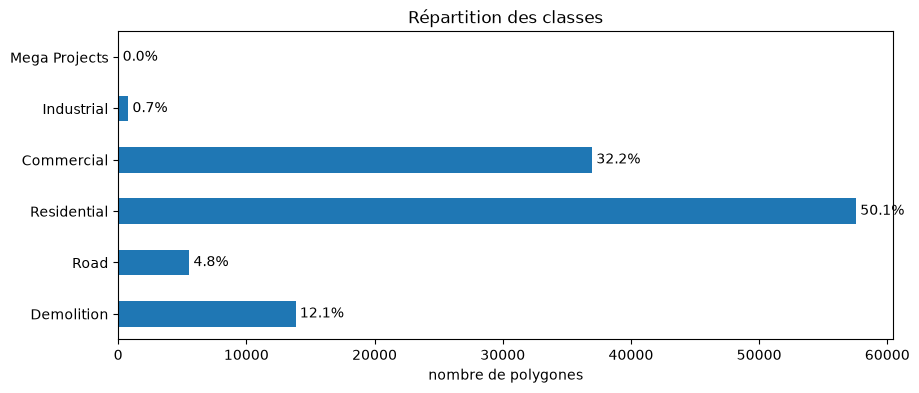

In [3]:
counts = pd.Series(y).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES, fill_value=0)
ax = counts.plot(kind='barh')
ax.set_title('Répartition des classes'); ax.set_xlabel('nombre de polygones')
for i, v in enumerate(counts):
    ax.text(v, i, f' {v / counts.sum():.1%}', va='center')
plt.show()

Les classes sont **fortement déséquilibrées** : les changements résidentiels et commerciaux dominent, tandis que les méga-projets et les zones industrielles sont rares. Un modèle qui ignorerait les classes rares obtiendrait une bonne *accuracy* mais un mauvais F1 macro : c'est pourquoi on suit cette métrique.

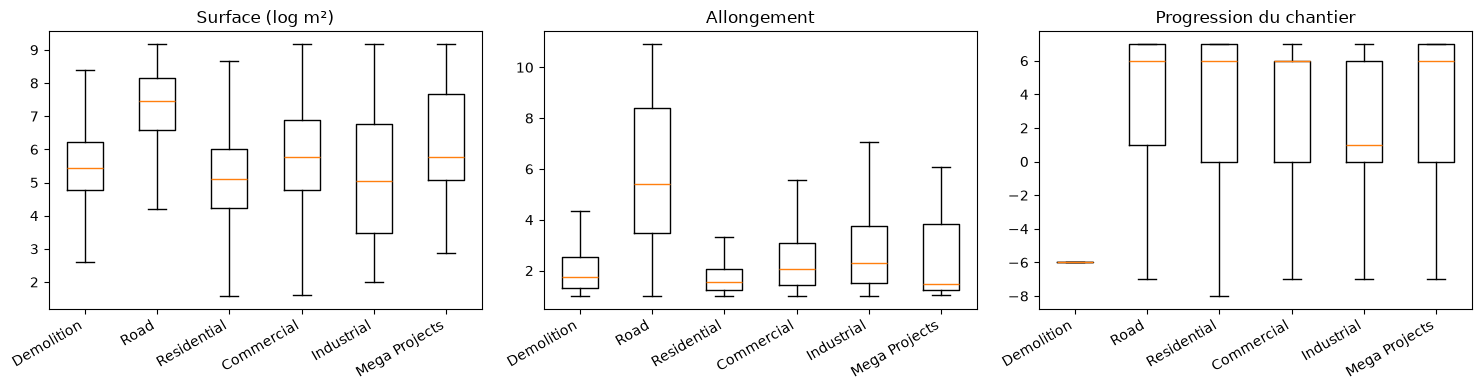

In [4]:
df_plot = X.assign(classe=pd.Series(y).map(dict(enumerate(CLASSES))).values)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, title) in zip(axes, [('log_area', 'Surface (log m²)'),
                                    ('elongation', 'Allongement'),
                                    ('status_progress', 'Progression du chantier')]):
    data = [df_plot.loc[df_plot['classe'] == c, col].dropna().clip(upper=df_plot[col].quantile(0.99))
            for c in CLASSES if (df_plot['classe'] == c).any()]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(data) + 1))
    ax.set_xticklabels([c for c in CLASSES if (df_plot['classe'] == c).any()], rotation=30, ha='right')
    ax.set_title(title)
plt.tight_layout(); plt.show()

La forme du polygone est un indice fort : une **route** est longue et étroite (allongement élevé), un **méga-projet** couvre une grande surface. La progression du chantier distingue les démolitions (un bâtiment présent au début) des constructions neuves.

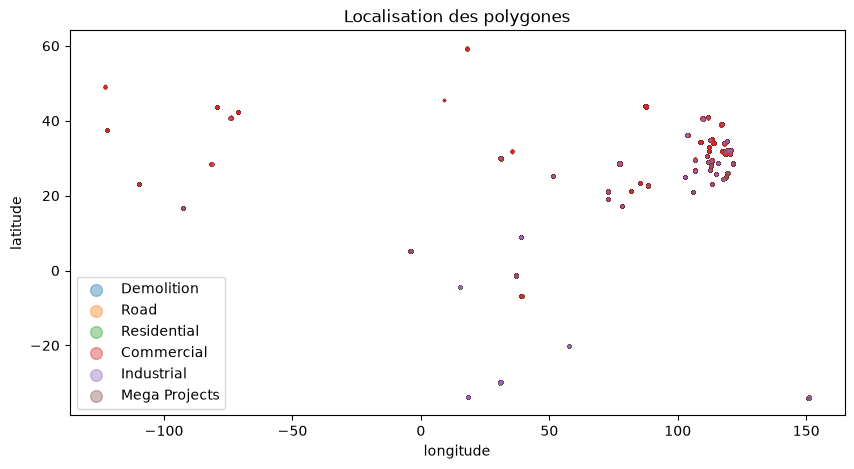

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for k, c in enumerate(CLASSES):
    m = y == k
    if m.any():
        ax.scatter(X.loc[m, 'lon'], X.loc[m, 'lat'], s=2, alpha=0.4, label=c)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Localisation des polygones'); ax.legend(markerscale=6)
plt.show()

Les polygones sont regroupés en **zones** : des sites répartis dans le monde entier, chacun photographié aux mêmes 5 dates. On identifie une zone par son ensemble de dates.

Ce regroupement a une conséquence importante pour l'évaluation : deux polygones d'une même zone partagent les mêmes images, le même contexte et souvent le même type de changement. Si l'un est dans l'entraînement et l'autre dans la validation, le modèle peut « reconnaître » la zone plutôt qu'apprendre à classer. On vérifie comment le jeu de test est construit :

In [6]:
overlap = np.isin(zones_test, zones).mean()
print(f'{overlap:.0%} des polygones de test appartiennent à une zone présente dans l\'entraînement')

28% des polygones de test appartiennent à une zone présente dans l'entraînement


On utilise donc deux validations croisées :
- **par zone** (`StratifiedGroupKFold`) : les zones de validation sont absentes de l'entraînement. C'est la mesure honnête de la capacité à traiter une **nouvelle** zone, et celle qui sert à choisir les modèles.
- **aléatoire** (`StratifiedKFold`) : reflète le classement Kaggle si le test partage ses zones avec l'entraînement, comme le montre le chiffre ci-dessus.

In [7]:
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_random = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate(model, cv, name, results):
    t = time.time()
    scores = cross_validate(model, X, y, groups=zones, cv=cv, n_jobs=1,
                            scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy'})
    results[name] = {'F1 macro': scores['test_f1_macro'].mean(),
                     'écart-type': scores['test_f1_macro'].std(),
                     'accuracy': scores['test_accuracy'].mean(),
                     'durée (s)': time.time() - t}
    print(f"{name:32s} F1 macro = {results[name]['F1 macro']:.3f} ± {results[name]['écart-type']:.3f}")

## 3. Comparaison des modèles

Tous les modèles sont évalués avec la validation croisée par zone :
- **Référence naïve** : prédit toujours la classe la plus fréquente
- **Régression logistique** : modèle linéaire, après imputation et standardisation
- **Random Forest** : forêt d'arbres de décision
- **Gradient boosting** (`HistGradientBoostingClassifier`) : arbres construits séquentiellement, chacun corrigeant les erreurs des précédents ; gère nativement les valeurs manquantes
- Les deux derniers **avec pondération des classes** (`class_weight='balanced'`), qui donne plus de poids aux erreurs sur les classes rares

In [8]:
models = {
    'Référence naïve': DummyClassifier(strategy='most_frequent'),
    'Régression logistique': make_pipeline(
        SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=N_JOBS, random_state=SEED)),
    'Random Forest équilibrée': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight='balanced_subsample',
                               n_jobs=N_JOBS, random_state=SEED)),
    'Gradient boosting': HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED),
    'Gradient boosting équilibré': HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                                                 class_weight='balanced', random_state=SEED),
}

results_group = {}
for name, model in models.items():
    evaluate(model, cv_group, name, results_group)

Référence naïve                  F1 macro = 0.111 ± 0.002
Régression logistique            F1 macro = 0.436 ± 0.007
Random Forest                    F1 macro = 0.477 ± 0.011
Random Forest équilibrée         F1 macro = 0.490 ± 0.011
Gradient boosting                F1 macro = 0.474 ± 0.013
Gradient boosting équilibré      F1 macro = 0.475 ± 0.012


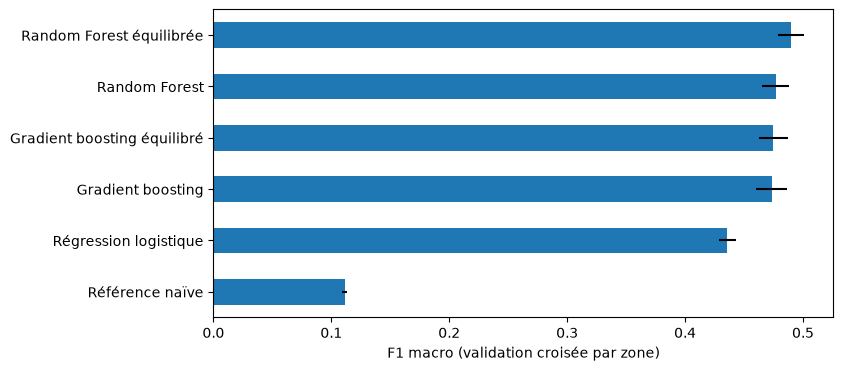

,F1 macro,écart-type,accuracy,durée (s)
Référence naïve,0.111,0.002,0.501,0.260
Régression logistique,0.436,0.007,0.581,20.771
Gradient boosting,0.474,0.013,0.708,14.239
Gradient boosting équilibré,0.475,0.012,0.658,56.690
Random Forest,0.477,0.011,0.726,72.986
Random Forest équilibrée,0.490,0.011,0.715,74.671


In [9]:
table = pd.DataFrame(results_group).T.sort_values('F1 macro')
ax = table['F1 macro'].plot(kind='barh', xerr=table['écart-type'], figsize=(8, 4))
ax.set_xlabel('F1 macro (validation croisée par zone)'); plt.show()
table.round(3)

**Lecture :** les modèles d'arbres dépassent nettement la régression logistique (0,44) et la référence naïve (0,11), ce qui confirme que les relations entre variables et classes ne sont pas linéaires. Entre Random Forest et gradient boosting, les écarts restent de l'ordre de 0,01 à 0,02, proches de la variabilité d'un pli à l'autre. La pondération des classes aide la Random Forest (+0,013) mais presque pas le gradient boosting.

## 4. Réglage des hyperparamètres

On règle le gradient boosting par une recherche aléatoire, toujours avec la validation par zone. Pour limiter le temps de calcul, la recherche porte sur un sous-échantillon de 60 000 polygones ; le meilleur réglage est ensuite réévalué sur l'ensemble des données.

In [10]:
rng = np.random.default_rng(SEED)
sub = rng.choice(len(X), size=min(60_000, len(X)), replace=False)

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
    param_distributions={
        'learning_rate': [0.03, 0.05, 0.1, 0.2],
        'max_leaf_nodes': [15, 31, 63, 127],
        'min_samples_leaf': [10, 20, 50, 100],
        'l2_regularization': [0.0, 0.1, 1.0, 10.0],
        'max_features': [0.5, 0.8, 1.0],
        'class_weight': [None, 'balanced'],
    },
    n_iter=12, scoring='f1_macro', cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=1)
search.fit(X.iloc[sub], y[sub], groups=zones[sub])
print('Meilleurs paramètres :', search.best_params_)
print(f'F1 macro sur le sous-échantillon : {search.best_score_:.3f}')

Path('models').mkdir(exist_ok=True)
pd.Series(search.best_params_).to_json('models/best_params.json')

Meilleurs paramètres : {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_features': 1.0, 'learning_rate': 0.05, 'l2_regularization': 1.0, 'class_weight': None}
F1 macro sur le sous-échantillon : 0.477


In [11]:
best_model = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED,
                                            **search.best_params_)
evaluate(best_model, cv_group, 'Gradient boosting réglé', results_group)
evaluate(best_model, cv_random, 'Gradient boosting réglé', results_random := {})
print(f"\nÉcart entre validation aléatoire et par zone : "
      f"{results_random['Gradient boosting réglé']['F1 macro'] - results_group['Gradient boosting réglé']['F1 macro']:+.3f}")

Gradient boosting réglé          F1 macro = 0.494 ± 0.005
Gradient boosting réglé          F1 macro = 0.543 ± 0.002

Écart entre validation aléatoire et par zone : +0.049


L'écart entre les deux validations mesure ce que le modèle gagne à avoir déjà « vu » une zone : ici environ **+0,05** de F1 macro (0,54 contre 0,49). Le score par zone est la bonne estimation pour un usage sur de nouvelles régions ; le score aléatoire se rapproche du classement Kaggle, dans la mesure où le test partage des zones avec l'entraînement.

## 5. Analyse des erreurs

               precision    recall  f1-score   support

   Demolition      0.757     0.940     0.839     13859
         Road      0.798     0.575     0.668      5562
  Residential      0.791     0.766     0.778     57577
   Commercial      0.642     0.656     0.649     36987
   Industrial      0.387     0.015     0.029       802
Mega Projects      0.000     0.000     0.000        40

     accuracy                          0.737    114827
    macro avg      0.562     0.492     0.494    114827
 weighted avg      0.736     0.737     0.733    114827



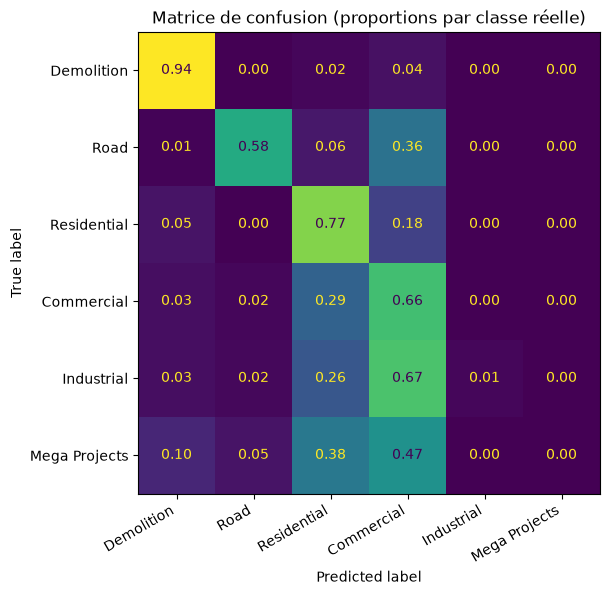

In [12]:
pred = cross_val_predict(best_model, X, y, groups=zones, cv=cv_group)
present = np.unique(y)
labels = [CLASSES[k] for k in present]

print(classification_report(y, pred, labels=present, target_names=labels, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=present, display_labels=labels,
                                        normalize='true', values_format='.2f', ax=ax, colorbar=False)
ax.set_title('Matrice de confusion (proportions par classe réelle)')
plt.xticks(rotation=30, ha='right'); plt.show()

Chaque ligne de la matrice montre, pour une classe réelle, comment le modèle répartit ses prédictions.

- Les **démolitions** sont très bien reconnues (rappel de 94 %) : le passage d'un bâtiment existant à un terrain dégagé laisse une trace nette dans les statuts et les couleurs.
- **Résidentiel et commercial** se confondent en partie : ce sont deux types de bâtiments qui se ressemblent vus du ciel.
- Les **routes** sont reconnues avec une bonne précision (80 %), mais une sur deux et demie est manquée.
- Les deux classes rares sont presque ignorées : **industriel** (802 exemples, F1 de 0,03) et **méga-projets** (40 exemples, F1 de 0). Ce sont elles qui limitent le F1 macro. Avec si peu d'exemples, surtout pour les méga-projets, le modèle a trop peu d'information pour les apprendre.

## 6. Importance des variables

On mesure l'importance par **permutation** : on mélange les valeurs d'une variable dans le jeu de validation et on regarde de combien le F1 macro baisse. Plutôt que variable par variable (beaucoup sont corrélées entre elles), on permute des **familles** de variables ensemble.

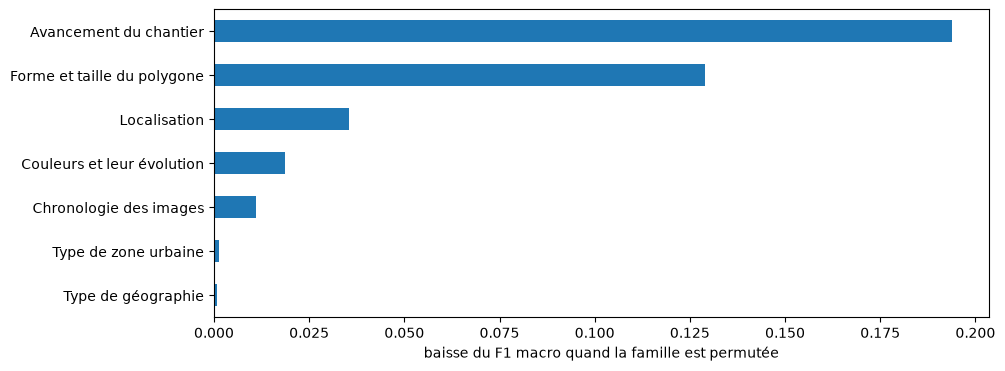

In [13]:
families = {
    'Type de zone urbaine': [c for c in X if c.startswith('urban_')],
    'Type de géographie': [c for c in X if c.startswith('geo_')],
    'Forme et taille du polygone': ['area_m2', 'log_area', 'perimeter_m', 'n_vertices',
                                    'compactness', 'elongation', 'rect_fill'],
    'Localisation': ['lon', 'lat'],
    'Chronologie des images': [c for c in X if c.startswith(('gap_', 'span_', 'first_date'))],
    'Avancement du chantier': [c for c in X if c.startswith(('status_', 'n_status_'))],
    'Couleurs et leur évolution': [c for c in X if c.startswith(('img_', 'brightness', 'color_', 'texture_'))],
}
assert sum(len(v) for v in families.values()) == X.shape[1]

train_idx, val_idx = next(cv_group.split(X, y, zones))
model = best_model.fit(X.iloc[train_idx], y[train_idx])
X_val, y_val = X.iloc[val_idx], y[val_idx]
baseline = f1_score(y_val, model.predict(X_val), average='macro')

drops = {}
for family, cols in families.items():
    scores = []
    for r in range(3):
        X_perm = X_val.copy()
        perm = np.random.default_rng(r).permutation(len(X_val))
        X_perm[cols] = X_val[cols].values[perm]
        scores.append(baseline - f1_score(y_val, model.predict(X_perm), average='macro'))
    drops[family] = np.mean(scores)

pd.Series(drops).sort_values().plot(kind='barh')
plt.xlabel('baisse du F1 macro quand la famille est permutée'); plt.show()

## 7. Soumission finale

Le modèle réglé est réentraîné sur l'ensemble des données d'entraînement, puis appliqué au jeu de test.

In [14]:
final_model = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, random_state=SEED,
                                             **search.best_params_).fit(X, y)
Path('submissions').mkdir(exist_ok=True)
submission = pd.DataFrame({'Id': test_ids, 'change_type': final_model.predict(X_test)})
submission.to_csv('submissions/submission.csv', index=False)
print(submission['change_type'].map(dict(enumerate(CLASSES))).value_counts())

change_type
Residential      56195
Commercial       42027
Demolition       14989
Road              7077
Industrial         229
Mega Projects        9
Name: count, dtype: int64


In [15]:
summary = pd.DataFrame(results_group).T[['F1 macro', 'écart-type', 'accuracy']]
summary.round(3)

,F1 macro,écart-type,accuracy
Référence naïve,0.111,0.002,0.501
Régression logistique,0.436,0.007,0.581
Random Forest,0.477,0.011,0.726
Random Forest équilibrée,0.490,0.011,0.715
Gradient boosting,0.474,0.013,0.708
Gradient boosting équilibré,0.475,0.012,0.658
Gradient boosting réglé,0.494,0.005,0.737


## 8. Conclusion et pistes

- **Meilleur modèle :** le gradient boosting réglé atteint un **F1 macro de 0,494** en validation par zone (accuracy de 74 %), contre 0,111 pour la référence naïve et 0,436 pour la régression logistique. La Random Forest équilibrée fait presque aussi bien (0,490).
- **La validation par zone est indispensable :** la validation aléatoire surestime le score d'environ 0,05, parce que le modèle profite des zones déjà vues.
- **Quatre classes sur six sont bien reconnues** (F1 de 0,65 à 0,84). Le F1 macro est limité par les classes industriel et méga-projets, presque jamais prédites faute d'exemples.
- Ces résultats portent sur 40 % des données d'entraînement (voir la note en introduction).

**Pistes d'amélioration :**
- Entraîner sur le **jeu complet**, qui contient 2,5 fois plus d'exemples des classes rares
- **Ajuster les seuils de décision** par classe pour mieux détecter industriel et méga-projets, quitte à perdre un peu de précision ailleurs
- Exploiter directement les **images** avec un réseau de neurones convolutif, au lieu de simples moyennes de couleur par polygone
- Ajouter le **contexte spatial** : types de changements des polygones voisins, densité de la zone
- Tester d'autres implémentations de boosting (LightGBM, XGBoost, CatBoost) et un ensemble de modèles